In [102]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [103]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt


In [104]:
cars=pd.read_csv('/content/drive/MyDrive/Machine learning files/datasets/used_cars.csv')
cars.head()

,price,year,manufacturer,model,condition,cylinders,fuel,odometer,transmission,drive,type,paint_color,state
0,17450,2023,toyota,RAV4,fair,4 cylinders,gas,61839.0,automatic,4wd,SUV,blue,oh
1,17600,2018,volkswagen,Tiguan,new,4 cylinders,gas,43226.0,automatic,rwd,SUV,silver,co
2,16450,2024,toyota,RAV4,fair,4 cylinders,gas,38581.0,manual,4wd,SUV,orange,co
3,22300,2025,hyundai,Sonata,good,4 cylinders,gas,0.0,automatic,fwd,sedan,silver,mi
4,26450,2021,chevrolet,Silverado 1500,excellent,8 cylinders,gas,89656.0,automatic,rwd,pickup,black,wa


In [105]:
cars.dropna(inplace=True)

In [106]:
#cylinders column
cars["cylinders"]=cars['cylinders'].str.replace('4 cylinders','4')
cars["cylinders"]=cars['cylinders'].str.replace('6 cylinders','6')
cars["cylinders"]=cars['cylinders'].str.replace('8 cylinders','8')
cars['cylinders']=cars['cylinders'].astype(float)

In [107]:
#state coloumn drop
cars=cars.drop('state',axis=1)

In [108]:
cars.head()

,price,year,manufacturer,model,condition,cylinders,fuel,odometer,transmission,drive,type,paint_color
0,17450,2023,toyota,RAV4,fair,4.0,gas,61839.0,automatic,4wd,SUV,blue
1,17600,2018,volkswagen,Tiguan,new,4.0,gas,43226.0,automatic,rwd,SUV,silver
2,16450,2024,toyota,RAV4,fair,4.0,gas,38581.0,manual,4wd,SUV,orange
3,22300,2025,hyundai,Sonata,good,4.0,gas,0.0,automatic,fwd,sedan,silver
4,26450,2021,chevrolet,Silverado 1500,excellent,8.0,gas,89656.0,automatic,rwd,pickup,black


In [109]:
cars=pd.get_dummies(cars,columns=['manufacturer','model','condition','fuel','transmission','drive','type','paint_color'])

In [110]:
cars.head()

,price,year,cylinders,odometer,manufacturer_BMW,manufacturer_CHEVROLET,manufacturer_FORD,manufacturer_HONDA,manufacturer_HYUNDAI,manufacturer_JEEP,...,paint_color_blue,paint_color_brown,paint_color_custom,paint_color_green,paint_color_grey,paint_color_orange,paint_color_red,paint_color_silver,paint_color_white,paint_color_yellow
0,17450,2023,4.0,61839.0,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
1,17600,2018,4.0,43226.0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,16450,2024,4.0,38581.0,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
3,22300,2025,4.0,0.0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
4,26450,2021,8.0,89656.0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [111]:
y=cars.iloc[:,0]
cars=cars.drop('price',axis=1)
cars.head()

,year,cylinders,odometer,manufacturer_BMW,manufacturer_CHEVROLET,manufacturer_FORD,manufacturer_HONDA,manufacturer_HYUNDAI,manufacturer_JEEP,manufacturer_KIA,...,paint_color_blue,paint_color_brown,paint_color_custom,paint_color_green,paint_color_grey,paint_color_orange,paint_color_red,paint_color_silver,paint_color_white,paint_color_yellow
0,2023,4.0,61839.0,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
1,2018,4.0,43226.0,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,2024,4.0,38581.0,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
3,2025,4.0,0.0,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
4,2021,8.0,89656.0,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [112]:
x=cars.iloc[:,0:]


In [113]:
#data spliting
x_train,x_temp,y_train,y_temp=train_test_split(x,y,test_size=0.2)
x_dev,x_test,y_dev,y_test=train_test_split(x_temp,y_temp,test_size=0.5)

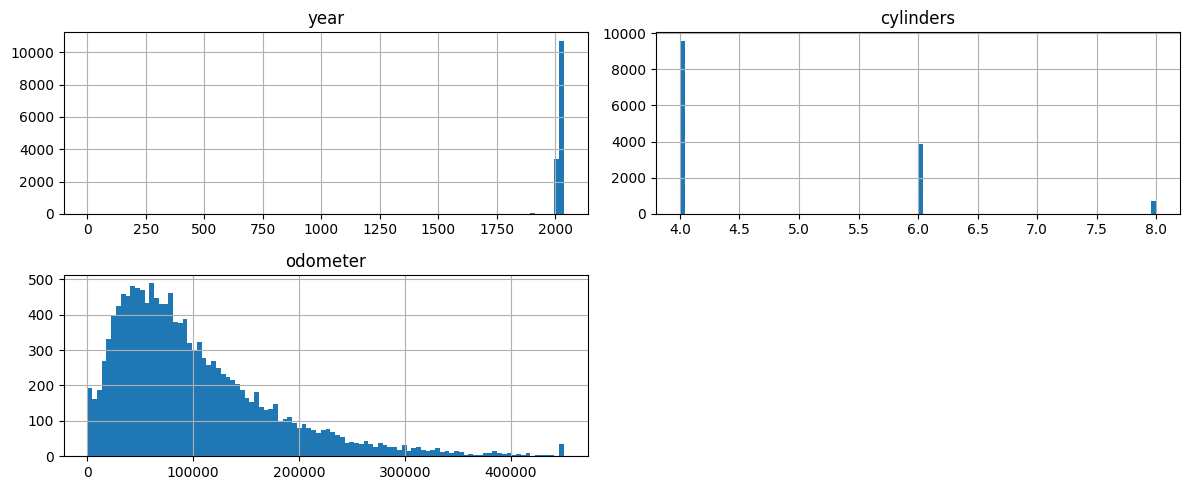

In [114]:

#UNSCALED training DATA VISUALIZATION

x_train.hist(bins=100,figsize=(12,5))
plt.title('TRAINING DATA DISTRIBUTION')
plt.tight_layout()
plt.show()

In [115]:
#DATA SCALING
#features
scaler1=StandardScaler()
x_train_scaled=scaler1.fit_transform(x_train)
x_dev_scaled=scaler1.transform(x_dev)
x_test_scaled=scaler1.transform(x_test)



In [116]:
y_train=y_train.values.reshape(-1,1)
y_dev=y_dev.values.reshape(-1,1)
y_test=y_test.values.reshape(-1,1)

In [117]:
#labels
scaler2=StandardScaler()
y_train_scaled=scaler2.fit_transform(y_train)
y_dev_scaled=scaler2.transform(y_dev)
y_test_scaled=scaler2.transform(y_test)

In [118]:
features_x=x_train.shape[1]
features_x

111

In [119]:
#x tensors
x_train_tensor=torch.tensor(x_train_scaled,dtype=torch.float32)
x_dev_tensor=torch.tensor(x_dev_scaled,dtype=torch.float32)
x_test_tensor=torch.tensor(x_test_scaled,dtype=torch.float32)

In [120]:
#y tensor
y_train_tensor=torch.tensor(y_train_scaled,dtype=torch.float32)
y_dev_tensor=torch.tensor(y_dev_scaled,dtype=torch.float32)
y_test_tensor=torch.tensor(y_test_scaled,dtype=torch.float32)

In [149]:
class cars_network(nn.Module):
  def __init__(self,features):
    super().__init__()
    self.layer1=nn.Linear(features,100)
    self.layer2=nn.Linear(100,100)
    self.layer3=nn.Linear(100,25)
    self.output_n=nn.Linear(25,1)
    self.relu=nn.ReLU()
  def forward(self,x):
    z1=self.layer1(x)
    a1=self.relu(z1)

    z2=self.layer2(a1)
    a2=self.relu(z2)

    z3=self.layer3(a2)
    a3=self.relu(z3)


    z4=self.output_n(a3)
    a4=z4  #linear activation

    return a4

torch.manual_seed(42)
model=cars_network(features_x)
loss=nn.MSELoss()
optimizer=torch.optim.SGD(model.parameters(),lr=0.2)



In [150]:
for epoch in range(1000):
  optimizer.zero_grad()

  prediction=model(x_train_tensor)

  loss_value=loss(prediction,y_train_tensor)

  loss_value.backward()

  optimizer.step()

  if epoch %100==0:
    print(f'epoc:{epoch}  loss:{loss_value.item():.2f}')



epoc:0  loss:1.02
epoc:100  loss:0.99
epoc:200  loss:0.98
epoc:300  loss:0.97
epoc:400  loss:0.96
epoc:500  loss:0.88
epoc:600  loss:0.61
epoc:700  loss:0.40
epoc:800  loss:0.41
epoc:900  loss:0.35


In [152]:
#DEV EVALUATION
model.eval()
with torch.no_grad():
  dev_prediction=model(x_dev_tensor)
  dev_loss=loss(dev_prediction,y_dev_tensor)
  print(dev_loss)

tensor(0.6163)


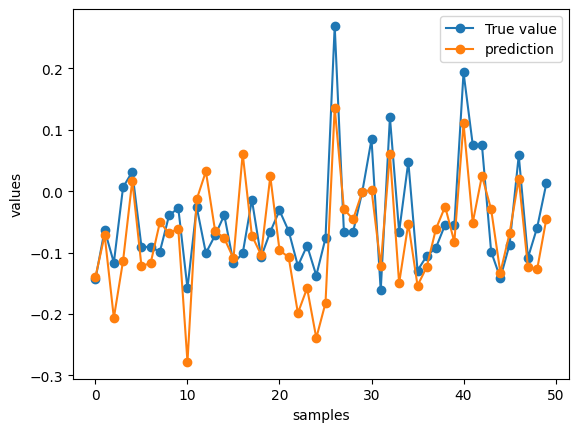

In [153]:
plt.plot(y_dev_tensor[:50],label='True value',marker='o')
plt.plot(dev_prediction[:50],label='prediction',marker='o')

plt.legend()
plt.xlabel("samples")
plt.ylabel('values')
plt.show()

In [155]:
#TEST EVALUATION
model.eval()
with torch.no_grad():
  test_prediction=model(x_test_tensor)
  test_loss=loss(test_prediction,y_test_tensor)
  print(test_loss)

tensor(0.4319)


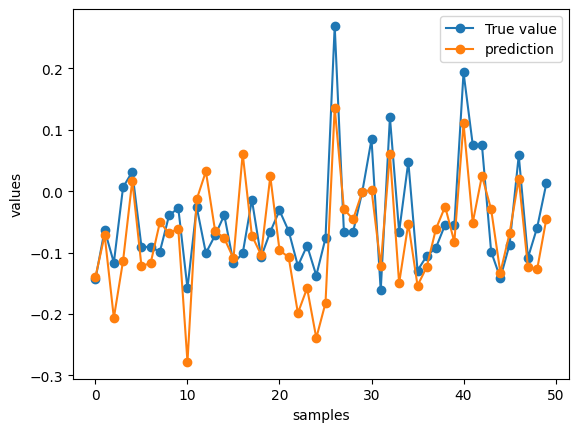

In [157]:
plt.plot(y_dev_tensor[:50],label='True value',marker='o')
plt.plot(dev_prediction[:50],label='prediction',marker='o')

plt.legend()
plt.xlabel("samples")
plt.ylabel('values')
plt.show()